# MACHINE LEARNING IN DATA SCIENCE — LAB 01
## End-to-End Machine Learning Project: House Price Prediction
**Tools:** Python 3.x, Scikit-learn, Pandas, NumPy, Matplotlib, Seaborn

| Student Name | Student Roll Number |
|---|---|
| Bùi Minh Hoàng | SE193392 |

# PART 1 — Environment Setup (10 pts)
## 1.1 Environment Setup
I created a separate Python environment for this lab and installed the libraries inside it:

```bash
python -m venv .venv
.venv\Scripts\activate
pip install numpy pandas matplotlib seaborn scikit-learn ipykernel
```

The cell below checks that all libraries can be imported.

In [1]:
# Run this cell to verify your environment
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn import __version__ as sk_version

print(f'NumPy:       {np.__version__}')
print(f'Pandas:      {pd.__version__}')
print(f'Scikit-learn:{sk_version}')
print('All libraries imported successfully!')

NumPy:       2.5.3
Pandas:      3.0.6
Scikit-learn:1.9.1
All libraries imported successfully!


# PART 2 — Exploratory Data Analysis (15 pts)
## 2.1 Dataset Overview (3 pts)

In [2]:
# Download the dataset (the lab template forgot this line)
housing = fetch_california_housing(as_frame=True)

df = housing.frame  # Contains both features and target

# TODO: Display shape, column types, missing values, and descriptive statistics
print('Shape:', df.shape)
print(df.dtypes)
print(df.isnull().sum())
df.describe()

Shape: (20640, 9)
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


**Answers**

1. **Instances and features:** 20,640 instances. There are 9 columns: 8 features (`MedInc`, `HouseAge`, `AveRooms`, `AveBedrms`, `Population`, `AveOccup`, `Latitude`, `Longitude`) and 1 target (`MedHouseVal`).
2. **Missing values:** No. `isnull().sum()` is 0 for every column.
3. **Range of MedInc:** from 0.4999 to 15.0001 (units of \$10,000).

## 2.2 Visualizations (8 pts — 2 pts each)

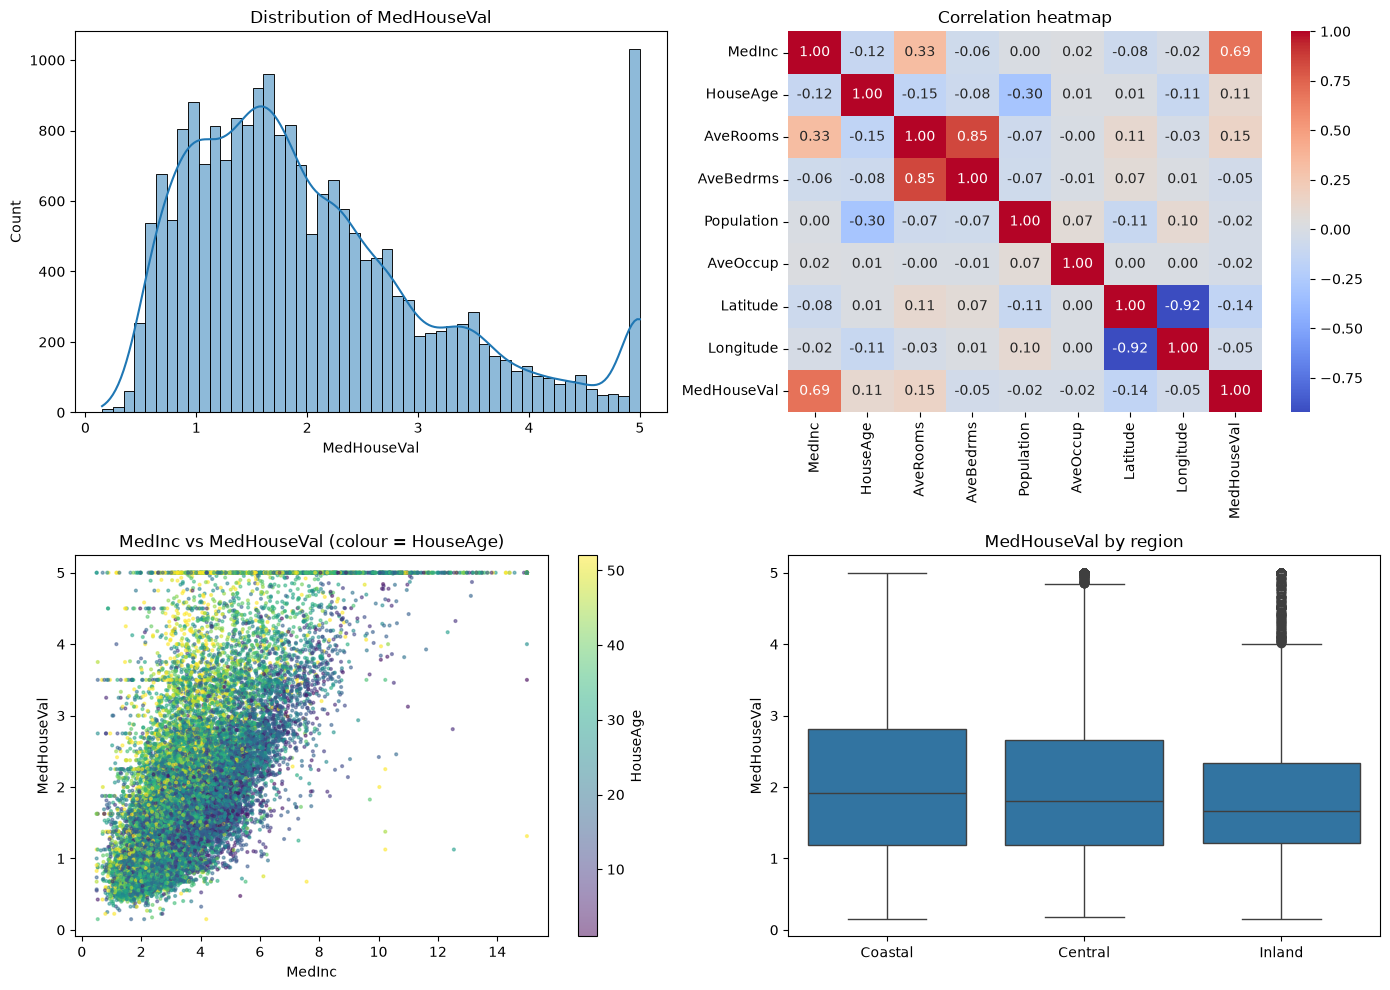

In [3]:
# Three regions by longitude: coastal (< -121), central (-121 to -118), inland (> -118)
region = np.where(df['Longitude'] < -121, 'Coastal',
                  np.where(df['Longitude'] > -118, 'Inland', 'Central'))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# TODO 1: Distribution of target
sns.histplot(df['MedHouseVal'], kde=True, bins=50, ax=axes[0, 0])
axes[0, 0].set_title('Distribution of MedHouseVal')

# TODO 2: Correlation heatmap
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[0, 1])
axes[0, 1].set_title('Correlation heatmap')

# TODO 3: Scatter MedInc vs MedHouseVal
points = axes[1, 0].scatter(df['MedInc'], df['MedHouseVal'], c=df['HouseAge'], s=4, alpha=0.5)
fig.colorbar(points, ax=axes[1, 0], label='HouseAge')
axes[1, 0].set_title('MedInc vs MedHouseVal (colour = HouseAge)')
axes[1, 0].set_xlabel('MedInc')
axes[1, 0].set_ylabel('MedHouseVal')

# TODO 4: Box plots by region
sns.boxplot(x=region, y=df['MedHouseVal'], order=['Coastal', 'Central', 'Inland'], ax=axes[1, 1])
axes[1, 1].set_title('MedHouseVal by region')
axes[1, 1].set_ylabel('MedHouseVal')

plt.tight_layout()
plt.savefig('eda_plots.png', dpi=120)
plt.show()

In [4]:
# A few numbers that I use in the interpretation below
print('Target mean:', round(df['MedHouseVal'].mean(), 2), ' median:', round(df['MedHouseVal'].median(), 2))
print('Rows with MedHouseVal = 5.0:', (df['MedHouseVal'] >= 5).sum())
print()
print(df.groupby(region)['MedHouseVal'].median())

Target mean: 2.07  median: 1.8
Rows with MedHouseVal = 5.0: 992

Central    1.8080
Coastal    1.9100
Inland     1.6695
Name: MedHouseVal, dtype: float64


**Interpretation / Insights**

1. **Distribution:** The target is skewed to the right (mean 2.07 is higher than median 1.80), so most houses are cheap and few are very expensive. There is a spike at 5.0 (992 rows) because values were capped at \$500,000.
2. **Heatmap:** `MedInc` is the only feature with a strong correlation with `MedHouseVal` (0.69); all other features are below 0.15. `Latitude` and `Longitude` are strongly negatively correlated with each other (-0.92), and so are `AveRooms` and `AveBedrms` positively (0.85).
3. **Scatter plot:** Higher income goes with a higher house value, and the trend is roughly linear. The flat line at 5.0 is the cap, and at the same income the older houses (yellow) tend to be a little more expensive than newer ones.
4. **Box plots:** The coastal region has the highest median (1.91), then central (1.81), then inland (1.67). The differences are small, so longitude alone is not enough to describe location.

## 2.3 Feature Correlation Analysis (4 pts)

In [5]:
# TODO: Compute and sort absolute correlations with target
correlations = df.corr()['MedHouseVal'].drop('MedHouseVal').abs().sort_values(ascending=False)
print(correlations.head(5))

MedInc       0.688075
AveRooms     0.151948
Latitude     0.144160
HouseAge     0.105623
AveBedrms    0.046701
Name: MedHouseVal, dtype: float64


**Top 3 features & justification**

1. **MedInc (0.69):** People with a higher income can pay more for a house, so areas with high income have expensive houses. It is by far the strongest feature.
2. **AveRooms (0.15):** More rooms means a bigger house, and bigger houses cost more.
3. **Latitude (0.14):** Location matters in real estate. The expensive areas (Los Angeles, San Diego) are in the south, which has lower latitude, so the correlation is negative.

# PART 3 — Data Preprocessing Pipeline (20 pts)
## 3.1 Train / Test Split (3 pts)

In [6]:
from sklearn.model_selection import train_test_split
import pandas as pd

# Create income category bins for stratification
df['income_cat'] = pd.cut(df['MedInc'], bins=[0, 1.5, 3.0, 4.5, 6.0, float('inf')],
                          labels=[1, 2, 3, 4, 5])

# TODO: Perform a stratified train/test split (80/20, random_state=42)
train_set, test_set = train_test_split(df, test_size=0.2, stratify=df['income_cat'], random_state=42)

# TODO: Remove the income_cat column from both sets
train_set = train_set.drop(columns='income_cat')
test_set = test_set.drop(columns='income_cat')

print(f'Training set: {len(train_set)} samples')
print(f'Test set:     {len(test_set)} samples')

Training set: 16512 samples
Test set:     4128 samples


In [7]:
# Check: share of each income category in the whole data and in the test set
print((df['income_cat'].value_counts(normalize=True).sort_index() * 100).round(1))

income_cat
1     4.0
2    31.9
3    35.1
4    17.6
5    11.4
Name: proportion, dtype: float64


**Why is stratified sampling preferred over a random split here? (2 pts)**

`MedInc` is the most important feature, and the income groups have very different sizes (group 1 is only 4% of the data, group 5 is 11%). A purely random split can accidentally put too few or too many houses of one income group in the test set, and then the test result is not representative. Stratified sampling keeps the same income proportions in the train set and the test set, so the test set is a good small copy of the full data.

## 3.2 Feature Engineering

### My own ideas (before reading the hints)
From the existing columns I thought of:
- **rooms per person** = `AveRooms / AveOccup`: how much space each person has.
- **bedrooms ratio** = `AveBedrms / AveRooms`: how many of the rooms are bedrooms.
- **distance to a big city** (Los Angeles or San Francisco) from `Latitude` and `Longitude`: houses near big cities are more expensive.

### Comparing with the hints
The hint gives `rooms_per_household`, `bedrooms_ratio` and `population_per_household`. `bedrooms_ratio` is the same as my second idea. In this scikit-learn version, `AveRooms` is already the number of rooms per household and `AveOccup` is already the number of people per household. So `rooms_per_household` and `population_per_household` will be the same as `AveRooms` and `AveOccup`. I still create them because the lab asks for them.

In [8]:
def add_features(df):
    df = df.copy()
    # TODO 1: Rooms per household
    df['rooms_per_household'] = df['AveRooms']
    # TODO 2: Bedrooms per room ratio
    df['bedrooms_ratio'] = df['AveBedrms'] / df['AveRooms']
    # TODO 3: Population per household
    df['population_per_household'] = df['AveOccup']
    return df

train_set = add_features(train_set)
test_set  = add_features(test_set)

# Check: how are the new features correlated with the target?
print(train_set[['rooms_per_household', 'bedrooms_ratio', 'population_per_household', 'MedHouseVal']].corr()['MedHouseVal'])

rooms_per_household         0.146255
bedrooms_ratio             -0.259934
population_per_household   -0.021991
MedHouseVal                 1.000000
Name: MedHouseVal, dtype: float64


**Explanation of the predictive value of each feature (3 pts)**

- **rooms_per_household:** It shows the size of the house, and bigger houses are more expensive (correlation 0.15). It is the same as `AveRooms`, so it gives no new information.
- **bedrooms_ratio:** A low ratio means the house has more non-bedroom rooms (living room, etc.), which is typical for bigger and richer homes. It has the strongest correlation of the three (-0.26) and it is the only really new feature.
- **population_per_household:** It shows how crowded a home is. Crowded homes are usually in poorer areas. It is the same as `AveOccup`, and its correlation is almost 0 (-0.02) because of a few extreme values (max 1243 people per household).

## 3.3 Full Preprocessing Pipeline (10 pts)

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

feature_cols = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms',
                'Population', 'AveOccup', 'Latitude', 'Longitude',
                'rooms_per_household', 'bedrooms_ratio', 'population_per_household']

X_train = train_set[feature_cols]
y_train = train_set['MedHouseVal']
X_test  = test_set[feature_cols]
y_test  = test_set['MedHouseVal']

# TODO: Build a Pipeline with SimpleImputer (median strategy) and StandardScaler
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
])

# TODO: Fit on training data and transform both sets
X_train_prepared = num_pipeline.fit_transform(X_train)
X_test_prepared  = num_pipeline.transform(X_test)

print('Pipeline applied. Training shape:', X_train_prepared.shape)

Pipeline applied. Training shape: (16512, 11)


The pipeline is fitted on the **training set only** (`fit_transform`), and the test set only uses `transform`. In this way the test set does not influence the mean and standard deviation used for scaling. The dataset has no missing values, so the imputer does not change anything, but it is kept because the lab asks for it.

# PART 4 — Regression Models (25 pts)
For every model I report RMSE, MAE and R² on the training set and the test set.

## 4.1 Linear Regression & Gradient Descent

In [10]:
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

results = {}   # keeps the numbers of every model for the table in 4.3

def evaluate_model(model, X_tr, y_tr, X_te, y_te, name):
    y_tr_pred = model.predict(X_tr)
    y_te_pred = model.predict(X_te)
    results[name] = {
        'Train RMSE': np.sqrt(mean_squared_error(y_tr, y_tr_pred)),
        'Test RMSE':  np.sqrt(mean_squared_error(y_te, y_te_pred)),
        'Train MAE':  mean_absolute_error(y_tr, y_tr_pred),
        'Test MAE':   mean_absolute_error(y_te, y_te_pred),
        'Train R2':   r2_score(y_tr, y_tr_pred),
        'Test R2':    r2_score(y_te, y_te_pred),
    }
    print(f'\n--- {name} ---')
    for k, v in results[name].items():
        print(f'{k}: {v:.4f}')

# TODO: Train a LinearRegression model
lr_model = LinearRegression()
lr_model.fit(X_train_prepared, y_train)
evaluate_model(lr_model, X_train_prepared, y_train, X_test_prepared, y_test, 'Linear Regression')

# TODO: Train an SGDRegressor with max_iter=1000, random_state=42
sgd_model = SGDRegressor(max_iter=1000, random_state=42)
sgd_model.fit(X_train_prepared, y_train)
evaluate_model(sgd_model, X_train_prepared, y_train, X_test_prepared, y_test, 'SGD Regressor')


--- Linear Regression ---
Train RMSE: 0.7184
Test RMSE: 0.7092
Train MAE: 0.5252
Test MAE: 0.5200
Train R2: 0.6145
Test R2: 0.6141

--- SGD Regressor ---
Train RMSE: 70712653.7801
Test RMSE: 9569008.5359
Train MAE: 4389695.9647
Test MAE: 3624985.1390
Train R2: -3735460241559722.0000
Test R2: -70256172387244.0391


**Note about SGD:** With the lab settings the SGD Regressor gives a huge error (RMSE about 7 × 10⁷, negative R²). SGD updates the weights after each sample, and a few samples have extreme values even after scaling (for example `AveOccup` is 107 standard deviations above the mean). With the default learning rate (`eta0=0.01`) these samples make the weights explode. A smaller learning rate fixes it, as shown below.

In [11]:
# Same model with a smaller learning rate
sgd_small = SGDRegressor(max_iter=1000, eta0=0.001, random_state=42)
sgd_small.fit(X_train_prepared, y_train)
evaluate_model(sgd_small, X_train_prepared, y_train, X_test_prepared, y_test, 'SGD Regressor (eta0=0.001)')


--- SGD Regressor (eta0=0.001) ---
Train RMSE: 0.7268
Test RMSE: 0.7183
Train MAE: 0.5275
Test MAE: 0.5228
Train R2: 0.6054
Test R2: 0.6041


**Analysis: Is Linear Regression underfitting, overfitting, or well-fitted? (3 pts)**

Linear Regression is **underfitting**.
- It is not overfitting, because the training and test results are almost the same: RMSE 0.7184 vs 0.7092 and R² 0.6145 vs 0.6141.
- But the results are not good on either set: R² is only 0.61, and the average error (RMSE 0.72, about \$72,000) is large compared with the median house value of \$180,000.
- A more complex model (the polynomial model in 4.2) gets a lower test error, so the straight-line model is too simple for this data.

The fixed SGD Regressor (RMSE 0.7183, R² 0.604) is almost the same as Linear Regression, because both minimise the same error.

## 4.2 Polynomial Regression & Learning Curves

In [12]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.model_selection import learning_curve

# TODO: Create a degree-2 polynomial pipeline and evaluate it
poly_pipeline = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('lin_reg', LinearRegression())
])
poly_pipeline.fit(X_train_prepared, y_train)
evaluate_model(poly_pipeline, X_train_prepared, y_train, X_test_prepared, y_test, 'Polynomial Regression (d=2)')


--- Polynomial Regression (d=2) ---
Train RMSE: 0.6395
Test RMSE: 0.6615
Train MAE: 0.4551
Test MAE: 0.4567
Train R2: 0.6945
Test R2: 0.6642


Linear Regression
  train RMSE: [0.7  0.69 0.68 0.68 0.71 0.71 0.72 0.72 0.72 0.72]
  valid RMSE: [1.8  2.36 2.4  2.   0.72 0.72 0.72 0.72 0.72 0.72]
Polynomial Regression (d=2)
  train RMSE: [0.6  0.6  0.6  0.6  0.61 0.62 0.63 0.63 0.63 0.64]
  valid RMSE: [246.85 299.35 259.99 184.21   2.28   2.64   1.25   1.14   1.42   1.44]


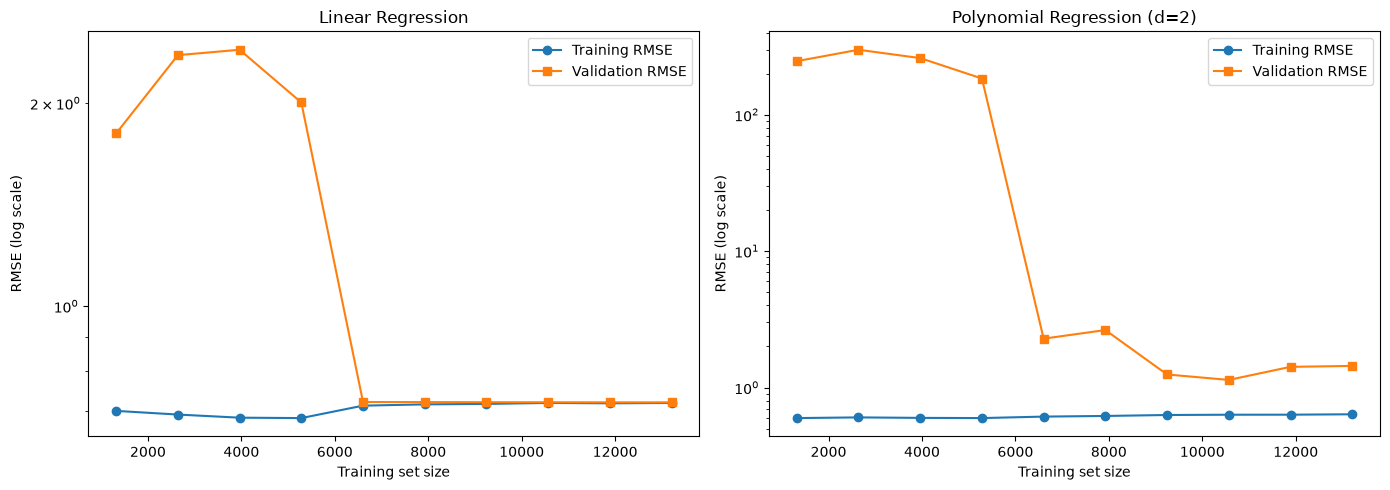

In [13]:
# TODO: Plot learning curves for both Linear and Polynomial models
# The scaling pipeline is put inside the model, so that each CV fold is scaled using only its own training part.
linear_full = Pipeline([('prep', num_pipeline), ('lin_reg', LinearRegression())])
poly_full = Pipeline([('prep', num_pipeline),
                      ('poly', PolynomialFeatures(degree=2, include_bias=False)),
                      ('lin_reg', LinearRegression())])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, model, title in [(axes[0], linear_full, 'Linear Regression'),
                         (axes[1], poly_full, 'Polynomial Regression (d=2)')]:
    sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train, cv=5, train_sizes=np.linspace(0.1, 1.0, 10),
        scoring='neg_root_mean_squared_error')
    train_rmse = -train_scores.mean(axis=1)
    val_rmse = -val_scores.mean(axis=1)
    ax.plot(sizes, train_rmse, 'o-', label='Training RMSE')
    ax.plot(sizes, val_rmse, 's-', label='Validation RMSE')
    ax.set_yscale('log')
    ax.set_title(title)
    ax.set_xlabel('Training set size')
    ax.set_ylabel('RMSE (log scale)')
    ax.legend()
    print(title)
    print('  train RMSE:', train_rmse.round(2))
    print('  valid RMSE:', val_rmse.round(2))

plt.tight_layout()
plt.savefig('learning_curves.png', dpi=120)
plt.show()

**What do the learning curves tell you about bias vs. variance? (4 pts)**

- **Linear Regression → high bias.** With 6,600 or more training samples, the training error (0.71) and the validation error (0.72) are almost equal and stay flat. Both are high, and more data does not help, so the model is too simple (high bias, low variance). (With fewer samples, the validation error is large because a few extreme rows are not in the small training subsets.)
- **Polynomial Regression → high variance.** Its training error is lower (0.64), so it fits the training data better (lower bias). But its validation error stays far above the training error (about 1.4 at the end), so it does not generalise well (high variance). The reason is that squaring the features makes the extreme rows even more extreme.

## 4.3 Regularized Models & Hyperparameter Tuning

In [14]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV

# TODO: Train Ridge and Lasso with default parameters
ridge = Ridge()
lasso = Lasso()
ridge.fit(X_train_prepared, y_train)
lasso.fit(X_train_prepared, y_train)
evaluate_model(ridge, X_train_prepared, y_train, X_test_prepared, y_test, 'Ridge (default)')
evaluate_model(lasso, X_train_prepared, y_train, X_test_prepared, y_test, 'Lasso')
print('\nNumber of non-zero Lasso coefficients:', np.sum(lasso.coef_ != 0))


--- Ridge (default) ---
Train RMSE: 0.7184
Test RMSE: 0.7092
Train MAE: 0.5252
Test MAE: 0.5200
Train R2: 0.6145
Test R2: 0.6141

--- Lasso ---
Train RMSE: 1.1570
Test RMSE: 1.1417
Train MAE: 0.9130
Test MAE: 0.9081
Train R2: 0.0000
Test R2: -0.0000

Number of non-zero Lasso coefficients: 0


In [15]:
# TODO: Use GridSearchCV to find the best alpha for Ridge
# (the scaling pipeline is inside the model, so the scaler is fitted again in every CV fold)
ridge_full = Pipeline([('prep', num_pipeline), ('ridge', Ridge())])
param_grid = {'ridge__alpha': [0.01, 0.1, 1, 10, 100]}
grid_search = GridSearchCV(ridge_full, param_grid, cv=5, scoring='neg_root_mean_squared_error')
grid_search.fit(X_train, y_train)
print('Best alpha:', grid_search.best_params_)
print('Best CV RMSE:', -grid_search.best_score_)

best_ridge = grid_search.best_estimator_
evaluate_model(best_ridge, X_train, y_train, X_test, y_test, 'Best Ridge')

Best alpha: {'ridge__alpha': 10}
Best CV RMSE: 0.7197263137287416

--- Best Ridge ---
Train RMSE: 0.7184
Test RMSE: 0.7092
Train MAE: 0.5251
Test MAE: 0.5200
Train R2: 0.6144
Test R2: 0.6141


In [16]:
# Comparison table
table = pd.DataFrame(results).T.round(4)
table.loc[['Linear Regression', 'SGD Regressor', 'Polynomial Regression (d=2)', 'Best Ridge', 'Lasso',
           'SGD Regressor (eta0=0.001)']]

,Train RMSE,Test RMSE,Train MAE,Test MAE,Train R2,Test R2
Linear Regression,7.184000e-01,7.092000e-01,5.252000e-01,5.200000e-01,6.145000e-01,6.141000e-01
SGD Regressor,7.071265e+07,9.569009e+06,4.389696e+06,3.624985e+06,-3.735460e+15,-7.025617e+13
Polynomial Regression (d=2),6.395000e-01,6.615000e-01,4.551000e-01,4.567000e-01,6.945000e-01,6.642000e-01
Best Ridge,7.184000e-01,7.092000e-01,5.251000e-01,5.200000e-01,6.144000e-01,6.141000e-01
Lasso,1.157000e+00,1.141700e+00,9.130000e-01,9.081000e-01,0.000000e+00,-0.000000e+00
SGD Regressor (eta0=0.001),7.268000e-01,7.183000e-01,5.275000e-01,5.228000e-01,6.054000e-01,6.041000e-01


**Comparison table (5 pts)** (RMSE and MAE are in units of \$100,000)

| Model | Train RMSE | Test RMSE | Train R² | Test R² | Test MAE |
|---|---|---|---|---|---|
| Linear Regression | 0.7184 | 0.7092 | 0.6145 | 0.6141 | 0.5200 |
| SGD Regressor (lab settings) | 7.07e+07 | 9.57e+06 | -3.7e+15 | -7.0e+13 | 3.6e+06 |
| Polynomial (d=2) | 0.6395 | **0.6615** | 0.6945 | **0.6642** | **0.4567** |
| Ridge (tuned, alpha=10) | 0.7184 | 0.7092 | 0.6144 | 0.6141 | 0.5200 |
| Lasso (default alpha=1) | 1.1570 | 1.1417 | 0.0000 | -0.0000 | 0.9081 |
| *SGD (eta0=0.001), extra* | 0.7268 | 0.7183 | 0.6054 | 0.6041 | 0.5228 |

**Which model performs best and why? (3 pts)**

**Polynomial Regression (d=2) is the best model.** It has the lowest test RMSE (0.6615), the lowest test MAE (0.4567, about \$46,000) and the highest test R² (0.664).
- It is better because the squared and interaction terms let it learn curved relationships that a straight line cannot, which fixes the underfitting of Linear Regression.
- **Ridge** is exactly the same as Linear Regression. The model does not overfit (16,512 samples, 11 features), so regularisation has nothing to fix; every alpha from 0.01 to 10 gives the same CV error (0.7197).
- **Lasso** with the default alpha=1 is too strong: all 11 coefficients become 0 and it just predicts the average price (R² = 0).
- **SGD** with the lab settings exploded (see 4.1).

# PART 5 — Classification Models (20 pts)

In [17]:
# Create binary labels
y_train_bin = (y_train >= 2.5).astype(int)
y_test_bin  = (y_test  >= 2.5).astype(int)

print('Class distribution (train):')
print(y_train_bin.value_counts(normalize=True))

Class distribution (train):
MedHouseVal
0    0.719295
1    0.280705
Name: proportion, dtype: float64


**Answers**

1. **Ratio:** 28% expensive (class 1) and 72% affordable (class 0), about 1 : 2.6. Yes, the dataset is **imbalanced**.
2. **Effect on metrics:** A model that always says "affordable" would already get 72% accuracy without finding any expensive house. So accuracy is misleading when classes are imbalanced. I look at **precision, recall (for the expensive class) and AUC-ROC** as well.

## 5.1 K-Nearest Neighbors & Naive Bayes

In [18]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.metrics import accuracy_score, precision_score, recall_score

clf_results = {}   # keeps the numbers of every classifier for the table in 5.3

def save_results(model, name):
    # accuracy, precision and recall of class 1 and AUC-ROC on the test set
    y_pred = model.predict(X_test_prepared)
    clf_results[name] = {
        'Accuracy':  accuracy_score(y_test_bin, y_pred),
        'Precision': precision_score(y_test_bin, y_pred),
        'Recall':    recall_score(y_test_bin, y_pred),
        'AUC-ROC':   roc_auc_score(y_test_bin, model.predict_proba(X_test_prepared)[:, 1]),
    }

# TODO: Train KNN with k=5 and evaluate
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_prepared, y_train_bin)

# TODO: Train Gaussian Naive Bayes and evaluate
gnb = GaussianNB()
gnb.fit(X_train_prepared, y_train_bin)

for model, name in [(knn, 'KNN (k=5)'), (gnb, 'Naive Bayes')]:
    y_pred = model.predict(X_test_prepared)
    print(f'\n=== {name} ===')
    print(classification_report(y_test_bin, y_pred))
    print(confusion_matrix(y_test_bin, y_pred))
    print('AUC-ROC:', roc_auc_score(y_test_bin, model.predict_proba(X_test_prepared)[:, 1]))
    save_results(model, name)


=== KNN (k=5) ===
              precision    recall  f1-score   support

           0       0.87      0.93      0.90      2934
           1       0.80      0.66      0.73      1194

    accuracy                           0.86      4128
   macro avg       0.84      0.80      0.81      4128
weighted avg       0.85      0.86      0.85      4128

[[2738  196]
 [ 400  794]]
AUC-ROC: 0.8891395171723193

=== Naive Bayes ===
              precision    recall  f1-score   support

           0       0.86      0.82      0.84      2934
           1       0.61      0.68      0.64      1194

    accuracy                           0.78      4128
   macro avg       0.74      0.75      0.74      4128
weighted avg       0.79      0.78      0.78      4128

[[2413  521]
 [ 386  808]]
AUC-ROC: 0.8111718556426759


### Optimal k for KNN (4 pts)

Best k: 9  CV accuracy: 0.8519


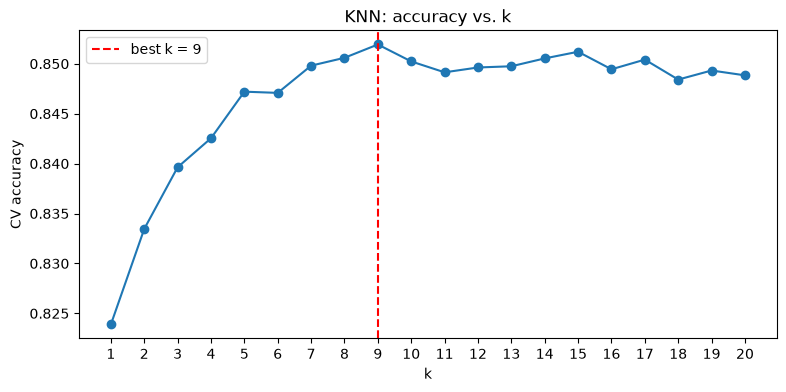

{'Accuracy': 0.8561046511627907, 'Precision': 0.8164556962025317, 'Recall': 0.6482412060301508, 'AUC-ROC': 0.908079936149733}


In [19]:
from sklearn.model_selection import cross_val_score

# 5-fold cross-validation on the training set for k = 1 to 20
# (the scaling pipeline is inside the model, so every fold is scaled correctly)
k_values = range(1, 21)
accuracies = []
for k in k_values:
    model = Pipeline([('prep', num_pipeline), ('knn', KNeighborsClassifier(n_neighbors=k))])
    scores = cross_val_score(model, X_train, y_train_bin, cv=5, scoring='accuracy')
    accuracies.append(scores.mean())

best_k = list(k_values)[int(np.argmax(accuracies))]
print('Best k:', best_k, ' CV accuracy:', round(max(accuracies), 4))

plt.figure(figsize=(9, 4))
plt.plot(k_values, accuracies, 'o-')
plt.axvline(best_k, color='red', linestyle='--', label=f'best k = {best_k}')
plt.xlabel('k')
plt.ylabel('CV accuracy')
plt.title('KNN: accuracy vs. k')
plt.xticks(list(k_values))
plt.legend()
plt.savefig('knn_k_selection.png', dpi=120)
plt.show()

# Train KNN again with the best k and evaluate it on the test set
knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train_prepared, y_train_bin)
save_results(knn_best, f'KNN (k={best_k})')
print(clf_results[f'KNN (k={best_k})'])

**Choice of k:** The best k is **9** (CV accuracy 0.852). With k=1 the accuracy is the lowest (0.824) because the model follows the noise of single points. Accuracy goes up until k=9 and then stays about the same (0.85), so a larger k brings no more gain. On the test set, k=9 has a higher AUC-ROC than k=5 (0.908 vs 0.889).

## 5.2 Decision Trees & Random Forests

In [20]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier

# TODO: Train a Decision Tree with max_depth=5
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train_prepared, y_train_bin)

# TODO: Print the tree structure (the numbers are in scaled units)
print(export_text(dt, feature_names=feature_cols))
save_results(dt, 'Decision Tree')

|--- MedInc <= 0.90
|   |--- AveOccup <= -0.06
|   |   |--- MedInc <= -0.39
|   |   |   |--- Latitude <= 1.06
|   |   |   |   |--- Longitude <= -1.36
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Longitude >  -1.36
|   |   |   |   |   |--- class: 0
|   |   |   |--- Latitude >  1.06
|   |   |   |   |--- bedrooms_ratio <= -0.56
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- bedrooms_ratio >  -0.56
|   |   |   |   |   |--- class: 0
|   |   |--- MedInc >  -0.39
|   |   |   |--- HouseAge <= -0.73
|   |   |   |   |--- MedInc <= 0.17
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- MedInc >  0.17
|   |   |   |   |   |--- class: 0
|   |   |   |--- HouseAge >  -0.73
|   |   |   |   |--- Latitude <= 1.10
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Latitude >  1.10
|   |   |   |   |   |--- class: 0
|   |--- AveOccup >  -0.06
|   |   |--- MedInc <= 0.27
|   |   |   |--- Longitude <= -1.41
|   |   |   |   |--- Latitude <= 1.20
|   |   |   |   |   |--- class: 1
|   

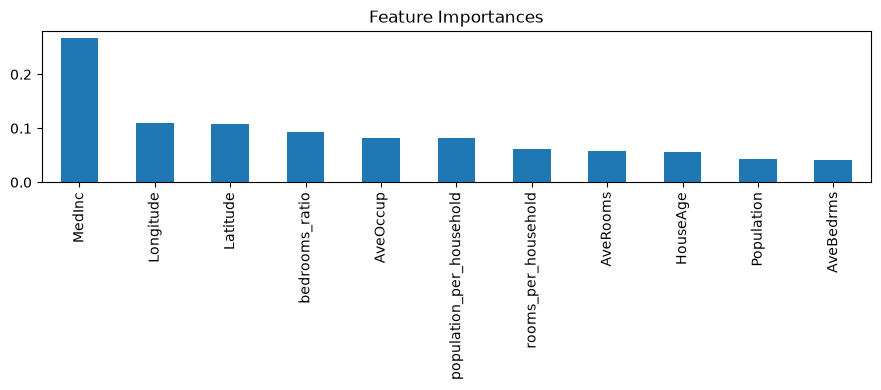

MedInc                      0.267
Longitude                   0.110
Latitude                    0.107
bedrooms_ratio              0.093
AveOccup                    0.083
population_per_household    0.081
rooms_per_household         0.061
AveRooms                    0.058
HouseAge                    0.056
Population                  0.043
AveBedrms                   0.042
dtype: float64


In [21]:
# TODO: Train a Random Forest with 100 trees
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_prepared, y_train_bin)
save_results(rf, 'Random Forest')

# TODO: Plot feature importance from Random Forest
importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
importances.plot(kind='bar', title='Feature Importances', figsize=(9, 4))
plt.tight_layout()
plt.savefig('feature_importances.png', dpi=120)
plt.show()
print(importances.round(3))

**Which features does the Random Forest consider most important? Does this align with the EDA? (3 pts)**

The most important feature is **`MedInc` (0.27)**, followed by `Longitude` (0.11), `Latitude` (0.11), `bedrooms_ratio` (0.09) and `AveOccup` (0.08).

- **Matches the EDA:** `MedInc` is first in both the correlation ranking and the forest. Latitude and Longitude together (0.22) show that location is the second most important factor, which fits the regional differences in the box plots.
- **Different from the EDA:** `AveOccup` had almost no correlation with the target (0.02) but the forest finds it important. Correlation only measures straight-line relationships, while trees can use non-linear splits.
- The new feature `bedrooms_ratio` is more important than `AveRooms` and `AveBedrms`, so it is useful.

## 5.3 Support Vector Machines
Both SVMs are trained on the whole training set (16,512 samples). It takes about 20 seconds for each, so I did not need the 5,000-sample subset.

In [22]:
from sklearn.svm import SVC
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)   # newer scikit-learn warns about probability=True

# TODO: Train SVM with RBF kernel
svm_rbf = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42)
svm_rbf.fit(X_train_prepared, y_train_bin)

# TODO: Train SVM with linear kernel
svm_lin = SVC(kernel='linear', C=1.0, probability=True, random_state=42)
svm_lin.fit(X_train_prepared, y_train_bin)

save_results(svm_rbf, 'SVM (RBF)')
save_results(svm_lin, 'SVM (Linear)')

# TODO: Compare AUC-ROC for both kernels
print('AUC-ROC RBF:   ', round(clf_results['SVM (RBF)']['AUC-ROC'], 4))
print('AUC-ROC Linear:', round(clf_results['SVM (Linear)']['AUC-ROC'], 4))

AUC-ROC RBF:    0.9373
AUC-ROC Linear: 0.926


In [23]:
# Classifier comparison table
order = ['KNN (k=5)', f'KNN (k={best_k})', 'Naive Bayes', 'Decision Tree', 'Random Forest',
         'SVM (RBF)', 'SVM (Linear)']
pd.DataFrame(clf_results).T.loc[order].round(4)

,Accuracy,Precision,Recall,AUC-ROC
KNN (k=5),0.8556,0.8020,0.6650,0.8891
KNN (k=9),0.8561,0.8165,0.6482,0.9081
Naive Bayes,0.7803,0.6080,0.6767,0.8112
Decision Tree,0.8600,0.8263,0.6533,0.8995
Random Forest,0.8997,0.8757,0.7613,0.9557
SVM (RBF),0.8777,0.8585,0.6910,0.9373
SVM (Linear),0.8641,0.8200,0.6792,0.9260


**Comparison table (5 pts)** (test set, positive class = expensive)

| Model | Accuracy | Precision | Recall | AUC-ROC |
|---|---|---|---|---|
| KNN (k=5) | 0.8556 | 0.8020 | 0.6650 | 0.8891 |
| KNN (optimal k=9) | 0.8561 | 0.8165 | 0.6482 | 0.9081 |
| Naive Bayes | 0.7803 | 0.6080 | 0.6767 | 0.8112 |
| Decision Tree | 0.8600 | 0.8263 | 0.6533 | 0.8995 |
| **Random Forest** | **0.8997** | **0.8757** | **0.7613** | **0.9557** |
| SVM (RBF) | 0.8777 | 0.8585 | 0.6910 | 0.9373 |
| SVM (Linear) | 0.8641 | 0.8200 | 0.6792 | 0.9260 |

The RBF kernel is better than the linear kernel (AUC-ROC 0.937 vs 0.926) because the boundary between cheap and expensive areas is not a straight line.

**Which classifier would you recommend for production use? (3 pts)**

I recommend the **Random Forest**.
- **Performance:** It is the best in every column of the table (accuracy 0.90, recall 0.76, AUC-ROC 0.956). The second best, SVM (RBF), has AUC-ROC 0.937 and recall 0.69.
- **Computational cost:** The forest trains in less than 1 second, while each SVM needs about 20 seconds, and the SVM also gets much slower when the data grows. KNN has to keep all training data and compare every new point with it.
- It also does not need feature scaling and shows which features are important.

# PART 6 — Report & Interpretation (10 pts)
Before writing the summary, two small checks to see which preprocessing steps matter (5-fold CV on the training set only):

In [24]:
# Check 1: scaling for KNN (k=5)
knn_no_scale = cross_val_score(KNeighborsClassifier(n_neighbors=5), X_train, y_train_bin, cv=5, scoring='accuracy')
knn_scaled = cross_val_score(Pipeline([('prep', num_pipeline), ('knn', KNeighborsClassifier(n_neighbors=5))]),
                             X_train, y_train_bin, cv=5, scoring='accuracy')
print('KNN accuracy without scaling:', knn_no_scale.mean().round(4))
print('KNN accuracy with scaling:   ', knn_scaled.mean().round(4))

# Check 2: feature engineering for Linear Regression (8 original features vs 11 features)
original_cols = feature_cols[:8]
lr_8_model = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()),
                       ('lr', LinearRegression())])
lr_8 = cross_val_score(lr_8_model, X_train[original_cols], y_train, cv=5, scoring='neg_root_mean_squared_error')
lr_11 = cross_val_score(linear_full, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
print('\nLinear Regression CV RMSE, 8 original features:', (-lr_8.mean()).round(4))
print('Linear Regression CV RMSE, 11 features:         ', (-lr_11.mean()).round(4))

KNN accuracy without scaling: 0.7285
KNN accuracy with scaling:    0.8472

Linear Regression CV RMSE, 8 original features: 0.7312
Linear Regression CV RMSE, 11 features:          0.7197


### Executive summary

The California Housing dataset has 20,640 census block groups with 8 numeric features and no missing values. Its main challenges are a skewed target that is capped at \$500,000, extreme outliers in the average columns (for example `AveOccup` up to 1,243), and the fact that only `MedInc` has a strong correlation with price (0.69).

The preprocessing step with the greatest effect was **scaling**: KNN accuracy increased from 0.73 to 0.85 after `StandardScaler`. Stratified splitting kept the income groups balanced in the test set. Feature engineering helped only a little (Linear Regression CV RMSE 0.731 to 0.720), because two of the three new features are copies of existing columns.

The best regression model is **Polynomial Regression (degree 2)** with test RMSE 0.66, MAE 0.46 and R² 0.66. In real terms the average error is about \$46,000–\$66,000, which is large compared with the median house value of \$180,000, so the model is only good for rough estimates of a neighbourhood, not for pricing a single house.

The best classification model is the **Random Forest** with accuracy 0.90, precision 0.88, recall 0.76 and AUC-ROC 0.956; it is fast and suits the task, but it still misses 24% of the expensive areas.

Two ways to improve: (1) apply a log transform to the skewed columns (AveRooms, Population, AveOccup) because extreme values hurt the linear, polynomial and SGD models; (2) try a boosting model such as gradient boosting for regression, since tree models handled the non-linear effects best.

# PART 7 — Bonus: Getting familiar with Git (5 pts)
These three commands are run in the project folder:

```bash
git init
git add lab1_notebook.ipynb
git commit -m "Lab1: complete supervised learning pipeline"
```